# VaDeSC on SUPPORT

Baselines, VaDeSC, cluster interpretation and the robustness experiments (leakage, seeds, number of clusters, survival distribution), plus the extra datasets.

The full run takes roughly 30-45 min on a laptop CPU. Set `QUICK = True` for a short check.

In [1]:
import sys
sys.path.append("..")

from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

from src.baselines import run_cox, run_rsf, run_weibull_aft
from src.data import load_sksurv, load_support, load_support_raw
from src.metrics import logrank_chi2
from src.vadesc import DEVICE, evaluate_vadesc, train_vadesc


from imputation.data_imputation import load_support_imputed

QUICK = False
EPOCHS = 60 if QUICK else 300
N_SEEDS = 3 if QUICK else 5
print("device:", DEVICE)

device: cuda


## Data

(9105, 47) | death rate 68.1% | median follow-up 233 days


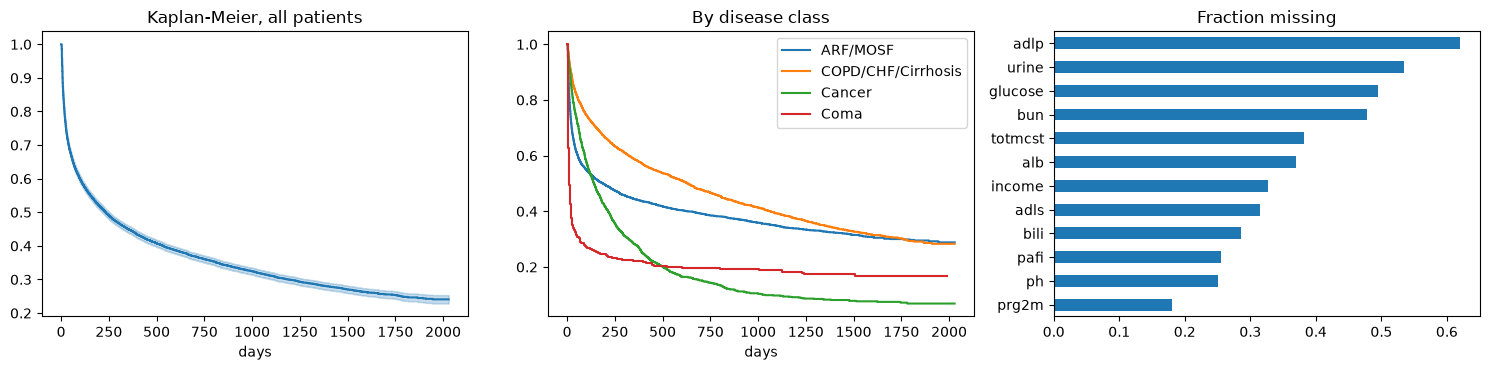

In [2]:
raw = load_support_raw()
print(raw.shape, f"| death rate {raw['death'].mean():.1%} | median follow-up {raw['d.time'].median():.0f} days")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
KaplanMeierFitter().fit(raw["d.time"], raw["death"]).plot_survival_function(ax=ax[0], legend=False)
ax[0].set(title="Kaplan-Meier, all patients", xlabel="days")
for dz, g in raw.groupby("dzclass"):
    KaplanMeierFitter(label=dz).fit(g["d.time"], g["death"]).plot_survival_function(ax=ax[1], ci_show=False)
ax[1].set(title="By disease class", xlabel="days")
raw.isna().mean().sort_values(ascending=False).head(12).plot.barh(ax=ax[2])
ax[2].set(title="Fraction missing"); ax[2].invert_yaxis()
plt.tight_layout(); plt.show()

In [3]:
support = load_support(drop_post_baseline=True)
support_vae = load_support_imputed("../data/support2_vae_imputed_baseline.csv")
print(f"train {support.X_tr.shape}, val {support.X_va.shape}, test {support.X_te.shape}")

train (6373, 51), val (911, 51), test (1821, 51)


## Baselines and VaDeSC

In [4]:
results = {
    "Cox PH": run_cox(support),
    "RSF": run_rsf(support),
    "Weibull AFT": run_weibull_aft(support),
}
vadesc = train_vadesc(support, K=4, d_lat=16, weibull_k=2.0, epochs=EPOCHS, verbose=True)  # configs/support.yml
results["VaDeSC"], clusters, z_te = evaluate_vadesc(vadesc, support)
pd.DataFrame(results).T.round(3)

epoch   25 | -ELBO    36.002 | val C-index 0.621
epoch   50 | -ELBO    35.039 | val C-index 0.626
epoch   75 | -ELBO    34.585 | val C-index 0.643
epoch  100 | -ELBO    34.292 | val C-index 0.644


KeyboardInterrupt: 

## Clusters

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for k in np.unique(clusters):
    m = clusters == k
    KaplanMeierFitter(label=f"cluster {k} (n={m.sum()})").fit(support.t_te[m], support.e_te[m]) \
        .plot_survival_function(ax=ax[0], ci_show=False)
ax[0].set(title=f"KM per cluster (test), log-rank chi2 = {logrank_chi2(support, clusters):.0f}", xlabel="days")
p = PCA(2).fit_transform(z_te)
sc = ax[1].scatter(p[:, 0], p[:, 1], c=clusters, s=6, cmap="tab10", alpha=0.7)
ax[1].set(title="Latent space (PCA)", xticks=[], yticks=[])
ax[1].legend(*sc.legend_elements(), title="cluster")
plt.tight_layout(); plt.show()

In [ ]:
# mean standardised feature value per cluster, 15 most different features
prof = pd.DataFrame(support.X_te, columns=support.features).groupby(clusters).mean()
top = prof.var().sort_values(ascending=False).index[:15]
fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(prof[top].to_numpy(), cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set(xticks=range(len(top)), yticks=range(len(prof)), ylabel="cluster")
ax.set_xticklabels(top, rotation=60, ha="right"); plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

pd.crosstab(pd.Series(clusters, name="cluster"), support.raw_te["dzclass"], normalize="index").round(2)

## Feature leakage

`sfdm2`, `slos`, `charges` and `totcst` are recorded after study entry. The `sfdm2` level `"<2 mo. follow-up"` mostly means the patient died within two months.

In [ ]:
support_clean = load_support(drop_post_baseline=True)
leak = {}
for name, d in [("paper preprocessing", support), ("baseline-only", support_clean)]:
    leak[(name, "Cox PH")] = run_cox(d)["C-index"]
    leak[(name, "RSF")] = run_rsf(d)["C-index"]
    leak[(name, "VaDeSC")] = evaluate_vadesc(train_vadesc(d, epochs=EPOCHS), d)[0]["C-index"]
pd.Series(leak).unstack(0).round(3)

## Stability across seeds

In [ ]:
runs = []
for s in range(N_SEEDS):
    m, cl, _ = evaluate_vadesc(train_vadesc(support, seed=s, epochs=EPOCHS), support)
    runs.append({"seed": s, **m, "clusters": cl})
runs = pd.DataFrame(runs)
ari = [adjusted_rand_score(a, b) for a, b in combinations(runs["clusters"], 2)]
print(f"C-index {runs['C-index'].mean():.3f} +/- {runs['C-index'].std():.3f}")
print(f"pairwise ARI {np.mean(ari):.2f} +/- {np.std(ari):.2f} (min {np.min(ari):.2f})")
print("cluster sizes:", [np.bincount(c).tolist() for c in runs["clusters"]])
runs.drop(columns="clusters").round(3)

## Number of clusters

In [ ]:
rows = []
for K in [1, 2, 3, 4, 6, 8]:
    model = train_vadesc(support, K=K, epochs=EPOCHS)
    m, cl, _ = evaluate_vadesc(model, support)
    rows.append({"K": K, **m, "used clusters": len(np.unique(cl)), "final -ELBO": model.history.train_loss.iloc[-1]})
pd.DataFrame(rows).set_index("K").round(3)

## Survival distribution and unsupervised clustering

In [ ]:
abl = {"Weibull k=2": results["VaDeSC"]}
abl["Weibull k=1"] = evaluate_vadesc(train_vadesc(support, weibull_k=1.0, epochs=EPOCHS), support)[0]
abl["log-normal"] = evaluate_vadesc(train_vadesc(support, dist="lognormal", epochs=EPOCHS), support)[0]
abl["VaDE (no survival)"], cl_vade, _ = evaluate_vadesc(train_vadesc(support, survival=False, epochs=EPOCHS), support)
cl_km = KMeans(4, n_init=10, random_state=42).fit(support.X_tr).predict(support.X_te)
abl["k-means"] = {"log-rank chi2": logrank_chi2(support, cl_km)}
print("ARI(VaDeSC, VaDE) =", round(adjusted_rand_score(clusters, cl_vade), 2),
      "| ARI(VaDeSC, k-means) =", round(adjusted_rand_score(clusters, cl_km), 2))
pd.DataFrame(abl).T.round(3)

## Other datasets

From scikit-survival. Smaller latent space as in the paper's FLChain config (`latent_dim=4, K=2, weibull_shape=1`).

In [ ]:
extra = {}
for name in ["FLChain", "GBSG2", "WHAS500"]:
    d = load_sksurv(name)
    extra[(name, "Cox PH")] = run_cox(d)
    extra[(name, "RSF")] = run_rsf(d)
    extra[(name, "VaDeSC")] = evaluate_vadesc(train_vadesc(d, K=2, d_lat=4, weibull_k=1.0, epochs=EPOCHS), d)[0]
pd.DataFrame(extra).T.round(3)